#**1.Modules import, Dataset loading and basic informations**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import math
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc, roc_curve
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Datasets/diabetes.csv")

In [3]:
df.head()

,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,NaN,NaN,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,NaN,NaN,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,185.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,NaN,NaN,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,NaN,NaN,44.0,41.0,300.0


In [4]:
df.shape

(403, 19)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        403 non-null    int64  
 1   chol      402 non-null    float64
 2   stab.glu  403 non-null    int64  
 3   hdl       402 non-null    float64
 4   ratio     402 non-null    float64
 5   glyhb     390 non-null    float64
 6   location  403 non-null    object 
 7   age       403 non-null    int64  
 8   gender    403 non-null    object 
 9   height    398 non-null    float64
 10  weight    402 non-null    float64
 11  frame     391 non-null    object 
 12  bp.1s     398 non-null    float64
 13  bp.1d     398 non-null    float64
 14  bp.2s     141 non-null    float64
 15  bp.2d     141 non-null    float64
 16  waist     401 non-null    float64
 17  hip       401 non-null    float64
 18  time.ppn  400 non-null    float64
dtypes: float64(13), int64(3), object(3)
memory usage: 59.9+ KB


In [6]:
df.describe()

,id,chol,stab.glu,hdl,ratio,glyhb,age,height,weight,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
count,403.000000,402.000000,403.000000,402.000000,402.000000,390.000000,403.000000,398.000000,402.000000,398.000000,398.000000,141.000000,141.000000,401.000000,401.000000,400.000000
mean,15978.310174,207.845771,106.672457,50.445274,4.521642,5.589769,46.851117,66.020101,177.592040,136.904523,83.321608,152.382979,92.524823,37.900249,43.039900,341.250000
std,11881.122124,44.445557,53.076655,17.262626,1.727886,2.242595,16.312333,3.918515,40.340666,22.741033,13.589227,21.712952,11.555198,5.729313,5.656713,309.540953
min,1000.000000,78.000000,48.000000,12.000000,1.500000,2.680000,19.000000,52.000000,99.000000,90.000000,48.000000,110.000000,60.000000,26.000000,30.000000,5.000000
25%,4792.500000,179.000000,81.000000,38.000000,3.200000,4.380000,34.000000,63.000000,151.000000,121.250000,75.000000,138.000000,84.000000,33.000000,39.000000,90.000000
50%,15766.000000,204.000000,89.000000,46.000000,4.200000,4.840000,45.000000,66.000000,172.500000,136.000000,82.000000,149.000000,92.000000,37.000000,42.000000,240.000000
75%,20336.000000,230.000000,106.000000,59.000000,5.400000,5.600000,60.000000,69.000000,200.000000,146.750000,90.000000,161.000000,100.000000,41.000000,46.000000,517.500000
max,41756.000000,443.000000,385.000000,120.000000,19.299999,16.110001,92.000000,76.000000,325.000000,250.000000,124.000000,238.000000,124.000000,56.000000,64.000000,1560.000000


#**2.Identify categorical and numerical columns**

In [7]:
# Identify categorical and numerical columns
categorical_cols = df.select_dtypes(include='object').columns.tolist()
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)


Categorical columns:
['location', 'gender', 'frame']

Numerical columns:
['id', 'chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'age', 'height', 'weight', 'bp.1s', 'bp.1d', 'bp.2s', 'bp.2d', 'waist', 'hip', 'time.ppn']


#**3.Checking Null Values**

In [8]:
df.isnull().sum()

,0
id,0
chol,1
stab.glu,0
hdl,1
ratio,1
glyhb,13
location,0
age,0
gender,0
height,5


#**4.Dropping columns with >50% null values**

In [9]:
df = df.drop(columns=['bp.2s', 'bp.2d'])
df.head()

,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,44.0,41.0,300.0


#**5.Imputation of other colums with less number of null values**

In [10]:
print("Missing values before imputation:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Impute missing values with the mean for numerical columns
for col in df.columns:
    if df[col].isnull().any(): # Check if the column has any missing values
        if df[col].dtype in ['int64', 'float64']:
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"Imputed column '{col}' with mean: {mean_value:.2f}")

print("\nMissing values after imputation:")
print(df.isnull().sum()[df.isnull().sum() > 0])

df.head()

Missing values before imputation:
chol         1
hdl          1
ratio        1
glyhb       13
height       5
weight       1
frame       12
bp.1s        5
bp.1d        5
waist        2
hip          2
time.ppn     3
dtype: int64
Imputed column 'chol' with mean: 207.85
Imputed column 'hdl' with mean: 50.45
Imputed column 'ratio' with mean: 4.52
Imputed column 'glyhb' with mean: 5.59
Imputed column 'height' with mean: 66.02
Imputed column 'weight' with mean: 177.59
Imputed column 'bp.1s' with mean: 136.90
Imputed column 'bp.1d' with mean: 83.32
Imputed column 'waist' with mean: 37.90
Imputed column 'hip' with mean: 43.04
Imputed column 'time.ppn' with mean: 341.25

Missing values after imputation:
frame    12
dtype: int64


,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,44.0,41.0,300.0


In [11]:
df.isnull().sum()


,0
id,0
chol,0
stab.glu,0
hdl,0
ratio,0
glyhb,0
location,0
age,0
gender,0
height,0


#**6.Imputing Missing Values in Categorical Column 'frame'**

As observed, the 'frame' column still contains 12 missing values. Since 'frame' is a categorical feature, we cannot impute it with a numerical mean. A common strategy for imputing missing categorical values is to replace them with the mode (the most frequent value) of that column.

In [12]:
mode_frame = df['frame'].mode()[0]
df['frame'] = df['frame'].fillna(mode_frame)

print(f"Imputed column 'frame' with mode: {mode_frame}")
print("\nMissing values after imputing 'frame':")
display(df.isnull().sum())



Imputed column 'frame' with mode: medium

Missing values after imputing 'frame':


,0
id,0
chol,0
stab.glu,0
hdl,0
ratio,0
glyhb,0
location,0
age,0
gender,0
height,0


In [13]:
df.shape

(403, 17)

#**7.Encoding categorical columns using label encoder**

In [14]:
categorical_cols_no_outliers = df.select_dtypes(include='object').columns.tolist()

df_ordinal_encoded = df.copy()

# Dictionary to store LabelEncoders for later use
label_encoders = {}

for col in categorical_cols_no_outliers:
    le = LabelEncoder()
    df_ordinal_encoded[col] = le.fit_transform(df_ordinal_encoded[col])
    label_encoders[col] = le # Store the fitted encoder

display(df_ordinal_encoded.head())

print("\nOrdinal Encoding Mappings:")
for col, encoder in label_encoders.items():
    print(f"Column '{col}':")
    for i, category in enumerate(encoder.classes_):
        print(f"  {category}: {i}")

,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,0,46,0,62.0,121.0,1,118.0,59.0,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,0,29,0,64.0,218.0,0,112.0,68.0,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,0,58,0,61.0,256.0,0,190.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,0,67,1,67.0,119.0,0,110.0,50.0,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,0,64,1,68.0,183.0,1,138.0,80.0,44.0,41.0,300.0



Ordinal Encoding Mappings:
Column 'location':
  Buckingham: 0
  Louisa: 1
Column 'gender':
  female: 0
  male: 1
Column 'frame':
  large: 0
  medium: 1
  small: 2


#**8. Creating the diabetes classifier column based on the glyhub index**

In [15]:
# Ensure 'diabetes' column is present before dropping NaNs and splitting data
# The 'glyhb' column from df_no_outliers is used to create the target variable
df_ordinal_encoded['diabetes'] = df['glyhb'].apply(lambda x: 1 if x > 6 else 0)
df_ordinal_encoded.shape

(403, 18)

#**9.Overall Correlation Matrix**

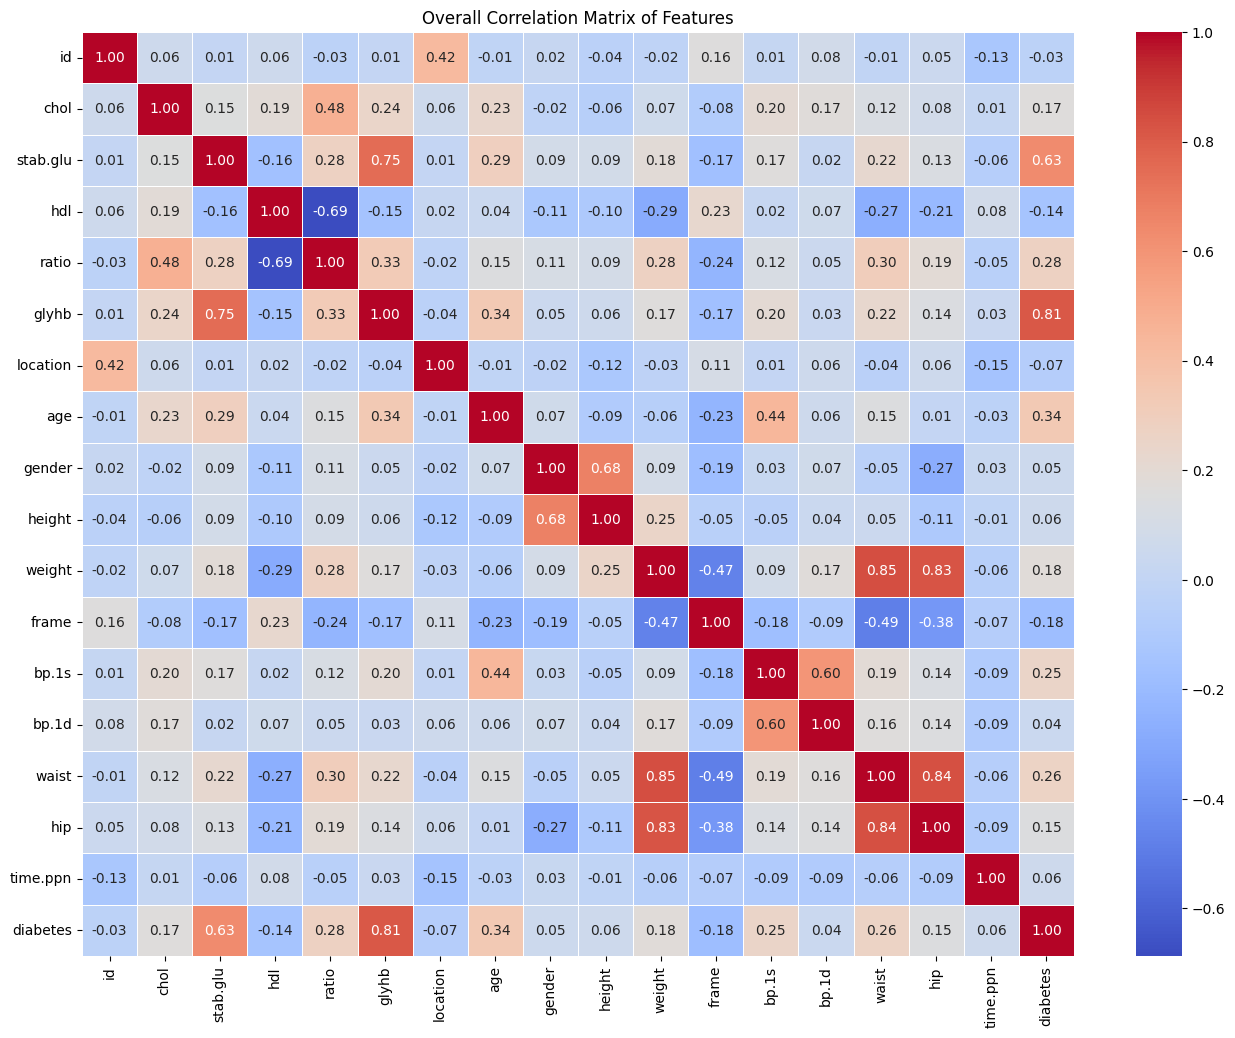

In [16]:
# Calculate the correlation matrix (assuming df_ordinal_encoded is the final preprocessed DataFrame)
correlation_matrix = df_ordinal_encoded.corr()

# Plotting the heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Overall Correlation Matrix of Features')
plt.show()

#**10.Feature Engineering using RF Feature Importance, Mutual Information scores and SHAP**

Feature Importances:
     Feature  Importance
4      glyhb    0.583629
1   stab.glu    0.195676
6        age    0.043823
3      ratio    0.038758
11     bp.1s    0.024372
13     waist    0.020051
2        hdl    0.019031
9     weight    0.014782
8     height    0.013930
0       chol    0.013029
14       hip    0.010579
15  time.ppn    0.008885
12     bp.1d    0.005662
10     frame    0.005283
7     gender    0.001345
5   location    0.001166


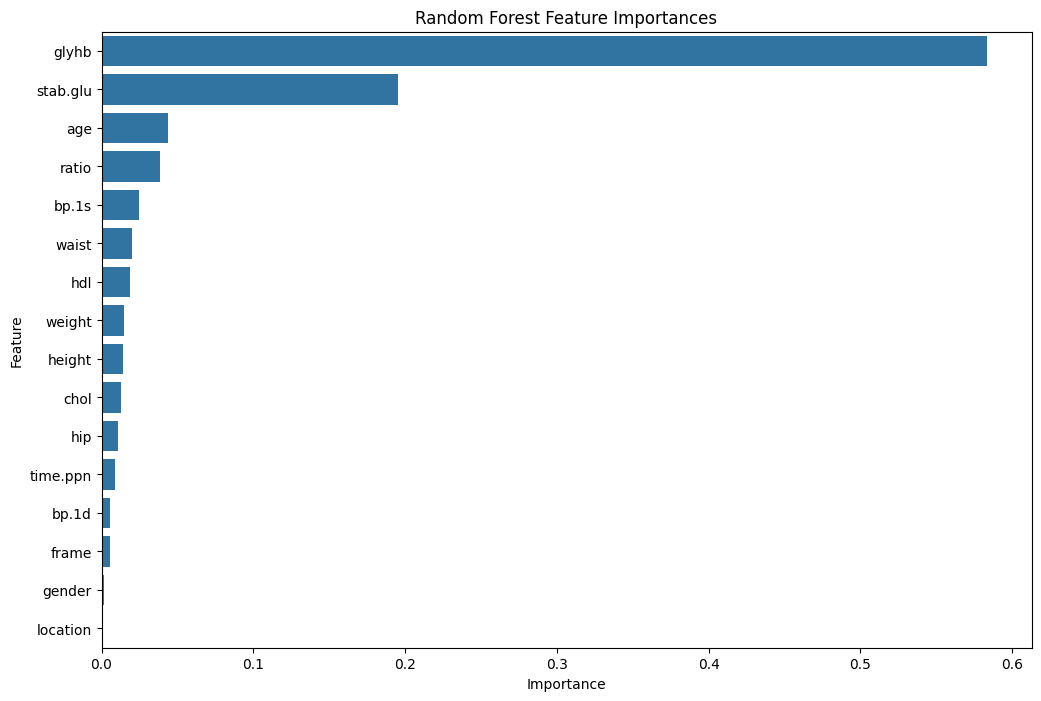

In [17]:
# Drop rows with NaN values from the final prepared DataFrame
df_check = df_ordinal_encoded.dropna()

# Drop the 'id' column and 'diabetes' (as it is the target variable) from the features
# 'glyhb' is now included in X as requested to consider 'all columns'
X = df_check.drop(columns=['id', 'diabetes'])
y = df_check['diabetes']

# Define columns to drop based on previous analysis (Random Forest Feature Importances or MI Scores)
#columns_to_drop = ['gender', 'frame', 'height', 'weight', 'waist', 'hip'] # These columns were identified for removal
#X = X.drop(columns=columns_to_drop, errors='ignore') # Use errors='ignore' to prevent error if column already dropped

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train a RandomForestClassifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Get feature importances
feature_importances = rf_classifier.feature_importances_

# Create a DataFrame for better visualization
features_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
})

# Sort features by importance
features_df = features_df.sort_values(by='Importance', ascending=False)

print("Feature Importances:")
print(features_df)

# Plotting feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=features_df)
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [18]:
from sklearn.feature_selection import mutual_info_classif

# Calculate Mutual Information scores
mi_scores = mutual_info_classif(X, y, random_state=42)

# Create a DataFrame for feature importances
mi_df = pd.DataFrame({'Feature': X.columns, 'MI_Score': mi_scores})

# Sort the DataFrame by MI_Score in descending order
mi_df = mi_df.sort_values(by='MI_Score', ascending=False)

print("Mutual Information Scores:")
print(mi_df)

Mutual Information Scores:
     Feature  MI_Score
4      glyhb  0.507080
1   stab.glu  0.226826
13     waist  0.077165
3      ratio  0.068019
6        age  0.053173
8     height  0.026280
12     bp.1d  0.025671
14       hip  0.023395
9     weight  0.014956
11     bp.1s  0.009017
2        hdl  0.006736
10     frame  0.002849
5   location  0.000245
0       chol  0.000000
7     gender  0.000000
15  time.ppn  0.000000


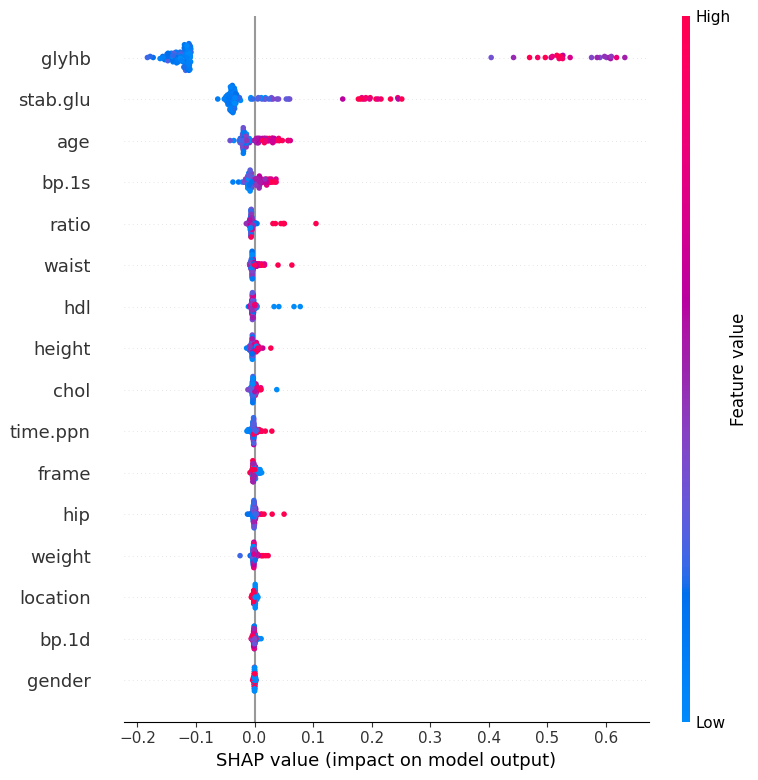

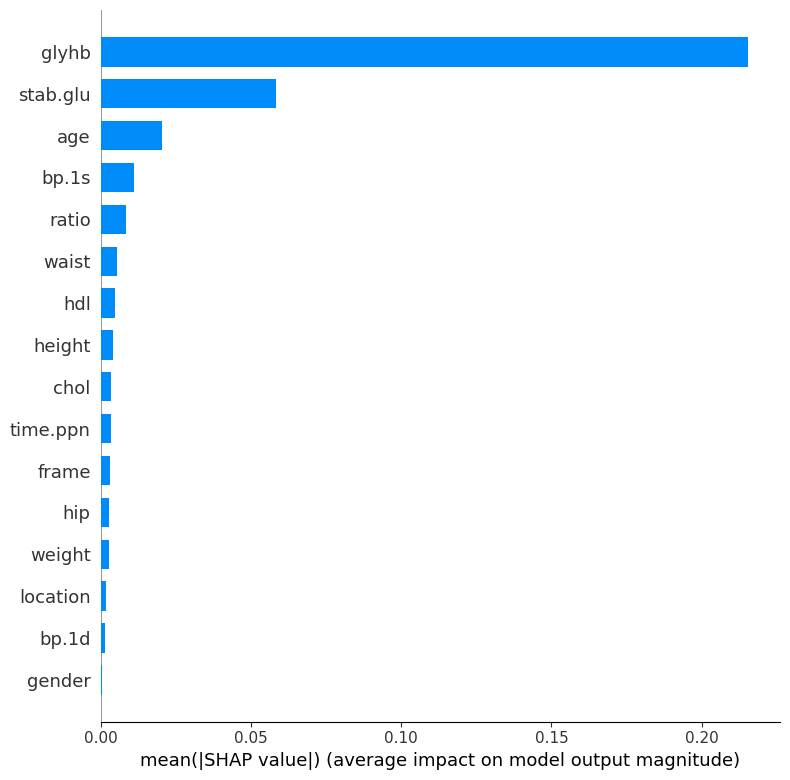

In [19]:
import shap

# Assuming rf_classifier, X_train, and X_test are already defined from previous steps

# Create a TreeExplainer object for the RandomForestClassifier
explainer = shap.TreeExplainer(rf_classifier)

# Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test)

# The shap_values for binary classification from TreeExplainer is often a list of two arrays,
# one for each class, or sometimes a 3D array (n_samples, n_features, n_classes).
# Based on the error, it's likely the latter.
# We are interested in the SHAP values for class 1 (diabetes)
# Correctly slice to get all samples, all features, for class 1.
shap_values_class_1 = shap_values[:, :, 1] if isinstance(shap_values, list) else shap_values[1] if isinstance(shap_values[0], list) else shap_values[:, :, 1]

# Visualize the SHAP values
# Summary plot shows how each feature impacts the model output
shap.summary_plot(shap_values_class_1, X_test, plot_type="dot")

# Another useful visualization is the bar plot of mean absolute SHAP values
shap.summary_plot(shap_values_class_1, X_test, plot_type="bar")

#**11.Dropping the unimportant columns based on importance score from feature engineering**

In [20]:
columns_to_drop = ['gender', 'frame', 'height', 'weight', 'waist', 'hip','location']
df_final = df_ordinal_encoded.drop(columns=columns_to_drop, errors='ignore')

print(f"DataFrame shape after dropping columns: {df_final.shape}")
print("Updated X head:")
display(df_final.head())

DataFrame shape after dropping columns: (403, 11)
Updated X head:


,id,chol,stab.glu,hdl,ratio,glyhb,age,bp.1s,bp.1d,time.ppn,diabetes
0,1000,203.0,82,56.0,3.6,4.31,46,118.0,59.0,720.0,0
1,1001,165.0,97,24.0,6.9,4.44,29,112.0,68.0,360.0,0
2,1002,228.0,92,37.0,6.2,4.64,58,190.0,92.0,180.0,0
3,1003,78.0,93,12.0,6.5,4.63,67,110.0,50.0,480.0,0
4,1005,249.0,90,28.0,8.9,7.72,64,138.0,80.0,300.0,1


#**12.Violin and Box plots for outlier detection**

In [21]:
# Get current numerical columns, excluding 'id'
current_numerical_cols = df_final.select_dtypes(include=['int64', 'float64']).columns.drop('id').tolist()

# Calculate grid dimensions to make it as square as possible
num_plots = len(current_numerical_cols)
num_cols = math.ceil(math.sqrt(num_plots))
num_rows = math.ceil(num_plots / num_cols)

# Create subplots
fig = make_subplots(
    rows=num_rows, cols=num_cols,
    subplot_titles=[f'Violin Plot of {col}' for col in current_numerical_cols]
)

# Add violin plots to the subplots
for i, col in enumerate(current_numerical_cols):
    row = (i // num_cols) + 1
    col_idx = (i % num_cols) + 1
    fig.add_trace(go.Violin(y=df_final[col], name=col, box_visible=True, meanline_visible=True), row=row, col=col_idx)

fig.update_layout(height=400 * num_rows, width=400 * num_cols, title_text='Violin Plots of Numerical Features', showlegend=False)
fig.show()

In [22]:
# Get current numerical columns, excluding 'id'
current_numerical_cols = df_final.select_dtypes(include=['int64', 'float64']).columns.drop('id').tolist()

# Calculate grid dimensions to make it as square as possible
num_plots = len(current_numerical_cols)
num_cols = math.ceil(math.sqrt(num_plots))
num_rows = math.ceil(num_plots / num_cols)

# Create subplots
fig = make_subplots(
    rows=num_rows, cols=num_cols,
    subplot_titles=[f'Box Plot of {col}' for col in current_numerical_cols]
)

# Add box plots to the subplots
for i, col in enumerate(current_numerical_cols):
    row = (i // num_cols) + 1
    col_idx = (i % num_cols) + 1
    fig.add_trace(go.Box(y=df_final[col], name=col, boxmean=True), row=row, col=col_idx)

fig.update_layout(height=400 * num_rows, width=400 * num_cols, title_text='Box Plots of Numerical Features', showlegend=False)
fig.show()

#**13.Identifying and removing outliers**

In [23]:
outliers = {}

# Get current numerical columns, excluding 'id' and 'diabetes'
current_numerical_cols_for_outliers = [col for col in df_final.select_dtypes(include=['int64', 'float64']).columns.drop('id').tolist() if col != 'diabetes']

for column in current_numerical_cols_for_outliers:
    Q1 = df_final[column].quantile(0.25)
    Q3 = df_final[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    column_outliers = df_final[(df_final[column] < lower_bound) | (df_final[column] > upper_bound)][column]

    if not column_outliers.empty:
        outliers[column] = list(zip(column_outliers.index, column_outliers.values))

print("Identified Outliers:")
for col, o_list in outliers.items():
    print(f"Column '{col}':")
    for idx, val in o_list:
        print(f"  Index {idx}: Value {val}")

Identified Outliers:
Column 'chol':
  Index 3: Value 78.0
  Index 62: Value 443.0
  Index 133: Value 318.0
  Index 147: Value 347.0
  Index 212: Value 342.0
  Index 294: Value 404.0
  Index 359: Value 307.0
  Index 377: Value 337.0
  Index 380: Value 322.0
Column 'stab.glu':
  Index 19: Value 206
  Index 22: Value 299
  Index 32: Value 330
  Index 39: Value 206
  Index 46: Value 193
  Index 47: Value 223
  Index 58: Value 233
  Index 60: Value 262
  Index 62: Value 185
  Index 67: Value 203
  Index 69: Value 184
  Index 86: Value 182
  Index 91: Value 197
  Index 99: Value 341
  Index 104: Value 176
  Index 108: Value 235
  Index 118: Value 173
  Index 129: Value 177
  Index 133: Value 270
  Index 138: Value 196
  Index 147: Value 197
  Index 150: Value 255
  Index 155: Value 342
  Index 161: Value 239
  Index 173: Value 385
  Index 176: Value 248
  Index 194: Value 371
  Index 198: Value 145
  Index 202: Value 174
  Index 209: Value 225
  Index 212: Value 251
  Index 213: Value 236
  

In [24]:
all_outlier_indices = set()
for col, o_list in outliers.items():
    for idx, val in o_list:
        all_outlier_indices.add(idx)

df_no_outliers = df_final.drop(index=list(all_outlier_indices))

print(f"Original DataFrame shape: {df_final.shape}")
print(f"DataFrame shape after removing outliers: {df_no_outliers.shape}")
df_no_outliers.head()

Original DataFrame shape: (403, 11)
DataFrame shape after removing outliers: (299, 11)


,id,chol,stab.glu,hdl,ratio,glyhb,age,bp.1s,bp.1d,time.ppn,diabetes
0,1000,203.0,82,56.0,3.6,4.31,46,118.000000,59.000000,720.0,0
1,1001,165.0,97,24.0,6.9,4.44,29,112.000000,68.000000,360.0,0
5,1008,248.0,94,69.0,3.6,4.81,34,132.000000,86.000000,195.0,0
6,1011,195.0,92,41.0,4.8,4.84,30,161.000000,112.000000,720.0,0
7,1015,227.0,75,44.0,5.2,3.94,37,136.904523,83.321608,1020.0,0


#**14.Box and violin plots after removing outliers**

In [25]:
# Get current numerical columns from df_no_outliers, excluding 'id' and 'diabetes'
current_numerical_cols_no_outliers = [col for col in df_no_outliers.select_dtypes(include=['int64', 'float64']).columns.drop('id').tolist() if col != 'diabetes']

# Calculate grid dimensions to make it as square as possible
num_plots = len(current_numerical_cols_no_outliers)
num_cols = math.ceil(math.sqrt(num_plots))
num_rows = math.ceil(num_plots / num_cols)

# Create subplots
fig = make_subplots(
    rows=num_rows, cols=num_cols,
    subplot_titles=[f'Violin Plot of {col}' for col in current_numerical_cols_no_outliers]
)

# Add violin plots to the subplots
for i, col in enumerate(current_numerical_cols_no_outliers):
    row = (i // num_cols) + 1
    col_idx = (i % num_cols) + 1
    fig.add_trace(go.Violin(y=df_no_outliers[col], name=col, box_visible=True, meanline_visible=True), row=row, col=col_idx)

fig.update_layout(height=400 * num_rows, width=400 * num_cols, title_text='Violin Plots of Numerical Features (No Outliers)', showlegend=False)
fig.show()

In [26]:
# Get current numerical columns from df_no_outliers, excluding 'id' and 'diabetes'
current_numerical_cols_no_outliers = [col for col in df_no_outliers.select_dtypes(include=['int64', 'float64']).columns.drop('id').tolist() if col != 'diabetes']

# Calculate grid dimensions to make it as square as possible
num_plots = len(current_numerical_cols_no_outliers)
num_cols = math.ceil(math.sqrt(num_plots))
num_rows = math.ceil(num_plots / num_cols)

# Create subplots
fig = make_subplots(
    rows=num_rows, cols=num_cols,
    subplot_titles=[f'Box Plot of {col}' for col in current_numerical_cols_no_outliers]
)

# Add box plots to the subplots
for i, col in enumerate(current_numerical_cols_no_outliers):
    row = (i // num_cols) + 1
    col_idx = (i % num_cols) + 1
    fig.add_trace(go.Box(y=df_no_outliers[col], name=col, boxmean=True), row=row, col=col_idx)

fig.update_layout(height=400 * num_rows, width=400 * num_cols, title_text='Box Plots of Numerical Features (No Outliers)', showlegend=False)
fig.show()

#**15.Correlation matrix of processed dataset and correlation values**

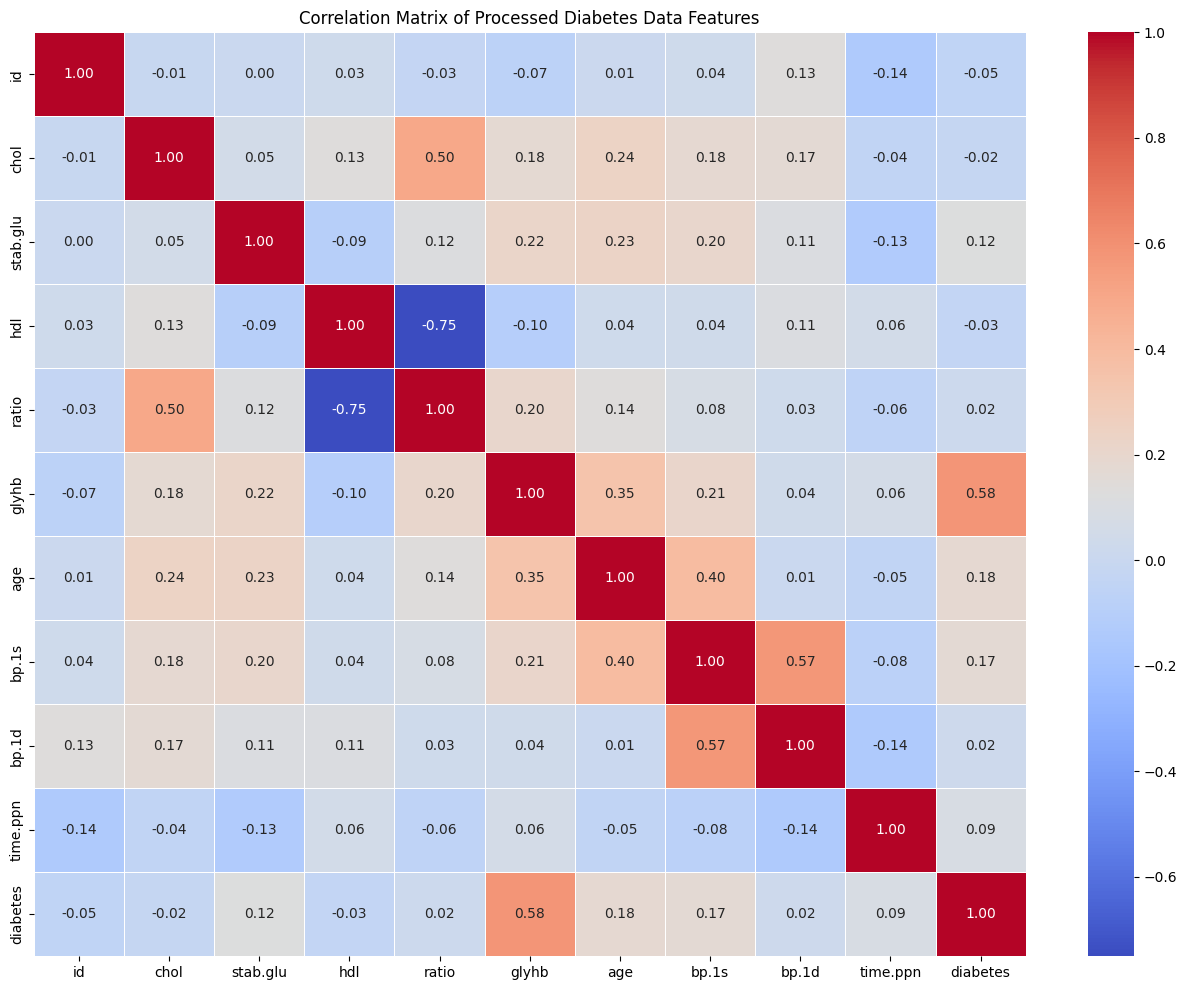

In [27]:
# Calculate the correlation matrix
correlation_matrix1 = df_no_outliers.corr()

# Plotting the heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix1, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Processed Diabetes Data Features')
plt.show()

In [28]:
import numpy as np

# Get the absolute values of the correlation matrix
abs_corr_matrix = correlation_matrix1.abs()

# Select upper triangle of correlation matrix
upp_tri_corr = abs_corr_matrix.where(np.triu(np.ones(abs_corr_matrix.shape), k=1).astype(bool))

# Stack the correlation matrix to get pairs and their values, then drop NA values
stacked_corr = upp_tri_corr.stack()

# Sort the correlations in descending order
sorted_corr = stacked_corr.sort_values(ascending=False)

print("Top 10 Most Correlated Pairs (Absolute Value):")
print(sorted_corr.head(10))

Top 10 Most Correlated Pairs (Absolute Value):
hdl       ratio       0.750699
glyhb     diabetes    0.581659
bp.1s     bp.1d       0.571523
chol      ratio       0.499743
age       bp.1s       0.397703
glyhb     age         0.348442
chol      age         0.236491
stab.glu  age         0.233670
          glyhb       0.218810
glyhb     bp.1s       0.208135
dtype: float64


In [29]:

negative_correlations = []

# Iterate through the sorted correlations (which are absolute values)
for pair, abs_corr_value in sorted_corr.items():
    if abs_corr_value > 0.40:
        col1, col2 = pair
        # Get the actual, signed correlation value
        actual_corr = correlation_matrix.loc[col1, col2]

        if actual_corr < 0:
            negative_correlations.append( (col1, col2, actual_corr) )


print("\nNegatively Correlated Pairs (Correlation < -0.40):")
for col1, col2, corr_value in negative_correlations:
    print(f"  {col1} - {col2}: {corr_value:.2f}")


Negatively Correlated Pairs (Correlation < -0.40):
  hdl - ratio: -0.69


#**16.Scatterplots between correlated features**

In [30]:
# Re-calculate correlation matrix using df_no_outliers
correlation_matrix_final = df_no_outliers.corr()

# Define the specific pairs the user wants to plot
# Note: Correlation values are dynamically fetched from the matrix for accuracy.
requested_pairs_list = [
    ('glyhb', 'diabetes'),
    ('stab.glu', 'glyhb'),
    ('hdl', 'ratio'),
    ('stab.glu', 'diabetes'),
    ('bp.1s', 'bp.1d'),
    ('chol', 'ratio'),
    ('age', 'bp.1s'),
    ('age', 'diabetes'),
    ('glyhb', 'age'),
    ('ratio', 'glyhb')
]

pairs_to_plot = []
seen_pairs = set()

for col1, col2 in requested_pairs_list:
    # Ensure both columns exist in df_no_outliers
    if col1 in df_no_outliers.columns and col2 in df_no_outliers.columns:
        actual_corr = correlation_matrix_final.loc[col1, col2]
        # Add canonical representation to avoid plotting (A,B) and (B,A) as separate plots
        canonical_pair = tuple(sorted((col1, col2)))

        if canonical_pair not in seen_pairs:
            pairs_to_plot.append((col1, col2, actual_corr))
            seen_pairs.add(canonical_pair)

# Calculate grid dimensions
num_plots = len(pairs_to_plot)
num_cols = 2 # Aim for 3 columns per row
num_rows = math.ceil(num_plots / num_cols)

fig = make_subplots(
    rows=num_rows, cols=num_cols,
    subplot_titles=[f'{col1} vs {col2} (Corr: {corr:.2f})' for col1, col2, corr in pairs_to_plot]
)

for i, (col1, col2, actual_corr) in enumerate(pairs_to_plot):
    row = (i // num_cols) + 1
    col_idx = (i % num_cols) + 1

    fig.add_trace(go.Scatter(
        x=df_no_outliers[col1],
        y=df_no_outliers[col2],
        mode='markers',
        name=f'{col1} vs {col2} (Corr: {actual_corr:.2f})',
        marker=dict(size=5, opacity=0.7)
    ),
    row=row, col=col_idx)

    fig.update_xaxes(title_text=col1, row=row, col=col_idx)
    fig.update_yaxes(title_text=col2, row=row, col=col_idx)

fig.update_layout(
    height=500 * num_rows,
    width=500 * num_cols,
    title_text='Scatter Plots of Specific Correlated Pairs in Processed Diabetes Data',
    showlegend=False
)
fig.show()

#**17.Saving the pre processed and clean dataset**

In [31]:
# Save the df_final DataFrame to a CSV file
output_filename = '/content/df_final_processed.csv'
df_no_outliers.to_csv(output_filename, index=False)

print(f"DataFrame successfully saved to {output_filename}")

DataFrame successfully saved to /content/df_final_processed.csv


#**18.Visualising the Imbalance in dataset**

In [32]:
df_no_outliers['diabetes'].value_counts()


,count
diabetes,
0,281
1,18


#**19.PCA+SMOTE**

Final dataset shape: (299, 9)

Class distribution:
 diabetes
0    281
1     18
Name: count, dtype: int64

Training class distribution:
diabetes
0    225
1     14
Name: count, dtype: int64

Number of PCA components selected: 7
Explained variance = 96.46%


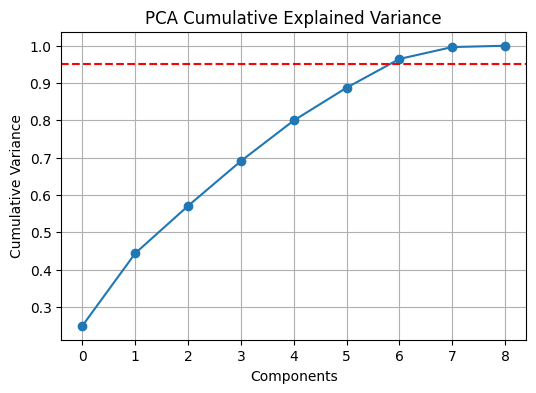


After SMOTE:
diabetes
0    225
1    225
Name: count, dtype: int64


In [33]:
# =================== FINAL PCA → SMOTE → ML PIPELINE =======================
# Uses your final dataset: df_no_outliers
# ==========================================================================


# -----------------------------
# 1. Prepare X, y (drop id)
# -----------------------------
df = df_no_outliers.copy()

X = df.drop(columns=['diabetes'])
if 'id' in X.columns:
    X = X.drop(columns=['id'])

y = df['diabetes'].astype(int)

print("Final dataset shape:", X.shape)
print("\nClass distribution:\n", y.value_counts())

# -----------------------------
# 2. Train-test split (stratified)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("\nTraining class distribution:")
print(y_train.value_counts())

# -----------------------------
# 3. Standardization
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# -----------------------------
# 4. PCA — Fit ONLY on training set
# -----------------------------

pca_temp = PCA()
pca_temp.fit(X_train_scaled)

explained = np.cumsum(pca_temp.explained_variance_ratio_)
n_components = np.searchsorted(explained, 0.95) + 1

print(f"\nNumber of PCA components selected: {n_components}")
print(f"Explained variance = {explained[n_components-1]*100:.2f}%")

pca = PCA(n_components=n_components)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

# Scree plot
plt.figure(figsize=(6,4))
plt.plot(explained, marker='o')
plt.axhline(0.95, color='r', linestyle='--')
plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Components")
plt.ylabel("Cumulative Variance")
plt.grid()
plt.show()

# -----------------------------
# 5. Apply SMOTE on PCA space (TRAIN ONLY)
# -----------------------------
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_pca, y_train)

print("\nAfter SMOTE:")
print(pd.Series(y_train_res).value_counts())




### Feature Contributions as Percentages per Principal Component

This section calculates and displays the percentage contribution of each original feature to its respective principal component, sorted by magnitude. This helps in understanding the primary drivers of each component.

In [34]:
# Get the PCA components (eigenvectors)
# pca.components_ is a 2D array, where rows are components and columns are original features
components_df = pd.DataFrame(
    pca.components_,
    columns=X.columns, # Use original feature names
    index=[f'Principal Component {i+1}' for i in range(pca.n_components_)]
)


print("\nFeature Contributions (Percentage) to Each Principal Component:")
for index, row in components_df.iterrows():
    # Get absolute contributions for the current component
    abs_contributions = row.abs()
    total_abs_contribution = abs_contributions.sum()

    if total_abs_contribution > 0:
        # Calculate percentage contributions
        percentage_contributions = (abs_contributions / total_abs_contribution) * 100
        # Sort in descending order
        sorted_percentages = percentage_contributions.sort_values(ascending=False)

        print(f"\n{index}:")
        for feature, percentage in sorted_percentages.items():
            print(f"  - {feature}: {percentage:.2f}%")
    else:
        print(f"\n{index}: No discernible contributions.")


Feature Contributions (Percentage) to Each Principal Component:

Principal Component 1:
  - ratio: 15.94%
  - bp.1s: 14.19%
  - age: 13.83%
  - glyhb: 13.42%
  - chol: 13.25%
  - stab.glu: 9.55%
  - hdl: 8.57%
  - bp.1d: 8.18%
  - time.ppn: 3.07%

Principal Component 2:
  - hdl: 25.99%
  - ratio: 21.81%
  - bp.1s: 18.38%
  - bp.1d: 17.71%
  - age: 7.18%
  - stab.glu: 4.39%
  - time.ppn: 3.63%
  - chol: 0.53%
  - glyhb: 0.38%

Principal Component 3:
  - bp.1d: 22.75%
  - age: 18.90%
  - glyhb: 15.09%
  - stab.glu: 11.09%
  - ratio: 9.54%
  - chol: 8.23%
  - time.ppn: 5.10%
  - bp.1s: 4.83%
  - hdl: 4.47%

Principal Component 4:
  - time.ppn: 27.62%
  - chol: 22.39%
  - stab.glu: 20.35%
  - hdl: 12.96%
  - glyhb: 5.60%
  - bp.1d: 5.00%
  - ratio: 3.03%
  - age: 1.94%
  - bp.1s: 1.11%

Principal Component 5:
  - time.ppn: 28.19%
  - chol: 22.74%
  - bp.1s: 14.82%
  - hdl: 13.53%
  - bp.1d: 9.64%
  - age: 3.81%
  - glyhb: 3.61%
  - ratio: 1.87%
  - stab.glu: 1.79%

Principal Component 6:


#**20.ML Model training**

In [35]:
# -----------------------------
# 6. Train ML Models
# -----------------------------
models = {
    'LogisticRegression': LogisticRegression(class_weight='balanced', max_iter=2000),
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
    'SVC': SVC(probability=True, class_weight='balanced', random_state=42),
    'KNeighbors': KNeighborsClassifier()
}

# XGBoost optional
try:
    from xgboost import XGBClassifier
    models['XGBoost'] = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
except:
    print("\nXGBoost not installed, skipping.")

results = {}

for name, clf in models.items():
    print(f"\n================ {name} ================")

    clf.fit(X_train_res, y_train_res)
    y_pred = clf.predict(X_test_pca)

    # probability
    try:
        y_proba = clf.predict_proba(X_test_pca)[:,1]
    except:
        y_proba = None

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    roc = roc_auc_score(y_test, y_proba) if y_proba is not None else None

    if y_proba is not None:
        precision, recall, _ = precision_recall_curve(y_test, y_proba)
        pr_auc = auc(recall, precision)
    else:
        pr_auc = None

    print(f"ROC AUC: {roc}")
    print(f"PR AUC: {pr_auc}")

    results[name] = {
        'model': clf,
        'roc_auc': roc,
        'pr_auc': pr_auc,
        'confusion_matrix': cm
    }



================ LogisticRegression ================

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        56
           1     1.0000    1.0000    1.0000         4

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60

Confusion Matrix:
 [[56  0]
 [ 0  4]]
ROC AUC: 1.0
PR AUC: 1.0

================ RandomForest ================

Classification Report:
              precision    recall  f1-score   support

           0     0.9649    0.9821    0.9735        56
           1     0.6667    0.5000    0.5714         4

    accuracy                         0.9500        60
   macro avg     0.8158    0.7411    0.7724        60
weighted avg     0.9450    0.9500    0.9466        60

Confusion Matrix:
 [[55  1]
 [ 2  2]]
ROC AUC: 0.9910714285714286
PR AUC: 0.8708333333333333

================ SVC ================



#**21.ROC & Precision-Recall Curves**

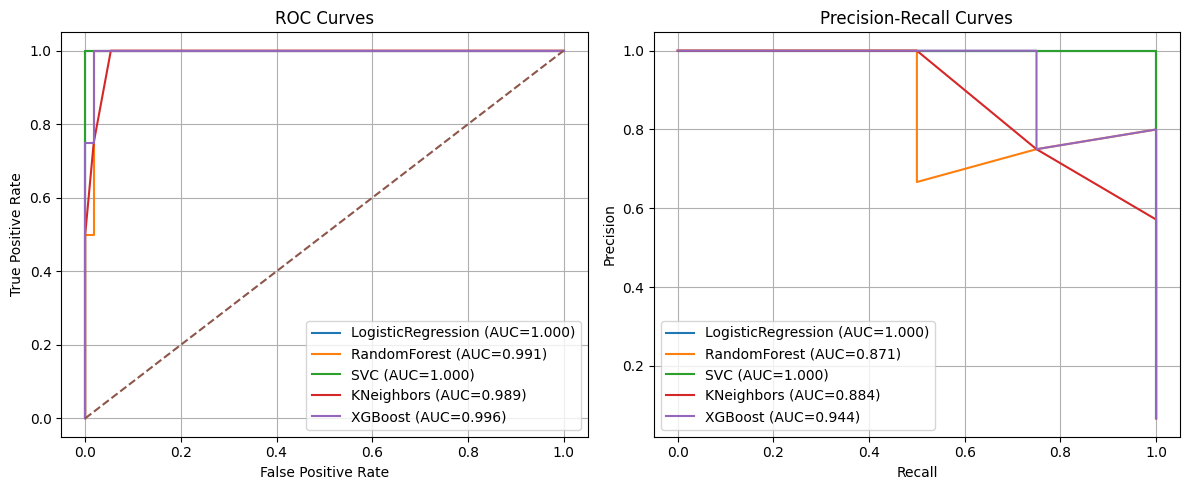

In [36]:
# -----------------------------
# 7. ROC & Precision-Recall Curves
# -----------------------------

plt.figure(figsize=(12,5))

# ROC curves
plt.subplot(1,2,1)
for name, info in results.items():
    clf = info['model']
    try:
        y_proba = clf.predict_proba(X_test_pca)[:,1]
        from sklearn.metrics import roc_curve
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        plt.plot(fpr, tpr, label=f"{name} (AUC={info['roc_auc']:.3f})")
    except:
        pass

plt.plot([0,1],[0,1],'--')
plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()

# PR curves
plt.subplot(1,2,2)
for name, info in results.items():
    clf = info['model']
    try:
        y_proba = clf.predict_proba(X_test_pca)[:,1]
        precision, recall, _ = precision_recall_curve(y_test, y_proba)
        pr_auc = auc(recall, precision)
        plt.plot(recall, precision, label=f"{name} (AUC={pr_auc:.3f})")
    except:
        pass

plt.title("Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# =====================================================================
# =================== END OF FINAL PIPELINE ===========================
# =====================================================================


#**22.ML Accuracy comparison**

In [37]:
# Extract model names and accuracies from the results dictionary
model_names = []
accuracies = []

for name, info in results.items():
    model_names.append(name)
    cm = info['confusion_matrix']
    # Calculate accuracy from the confusion matrix: (TP + TN) / (Total)
    accuracy = (cm[0, 0] + cm[1, 1]) / (cm[0, 0] + cm[0, 1] + cm[1, 0] + cm[1, 1])
    accuracies.append(accuracy)

# Create a bar plot
fig = go.Figure(
    data=[
        go.Bar(
            x=model_names,
            y=accuracies,
            text=[f'{acc:.4f}' for acc in accuracies],
            textposition='auto',
            marker_color=['blue', 'red', 'green', 'purple', 'orange']
        )
    ]
)

fig.update_layout(
    title_text='ML Model Accuracies Comparison',
    xaxis_title='Model',
    yaxis_title='Accuracy',
    yaxis_range=[0, 1] # Accuracy ranges from 0 to 1
)

fig.show()


#**23.Confusion matrices**

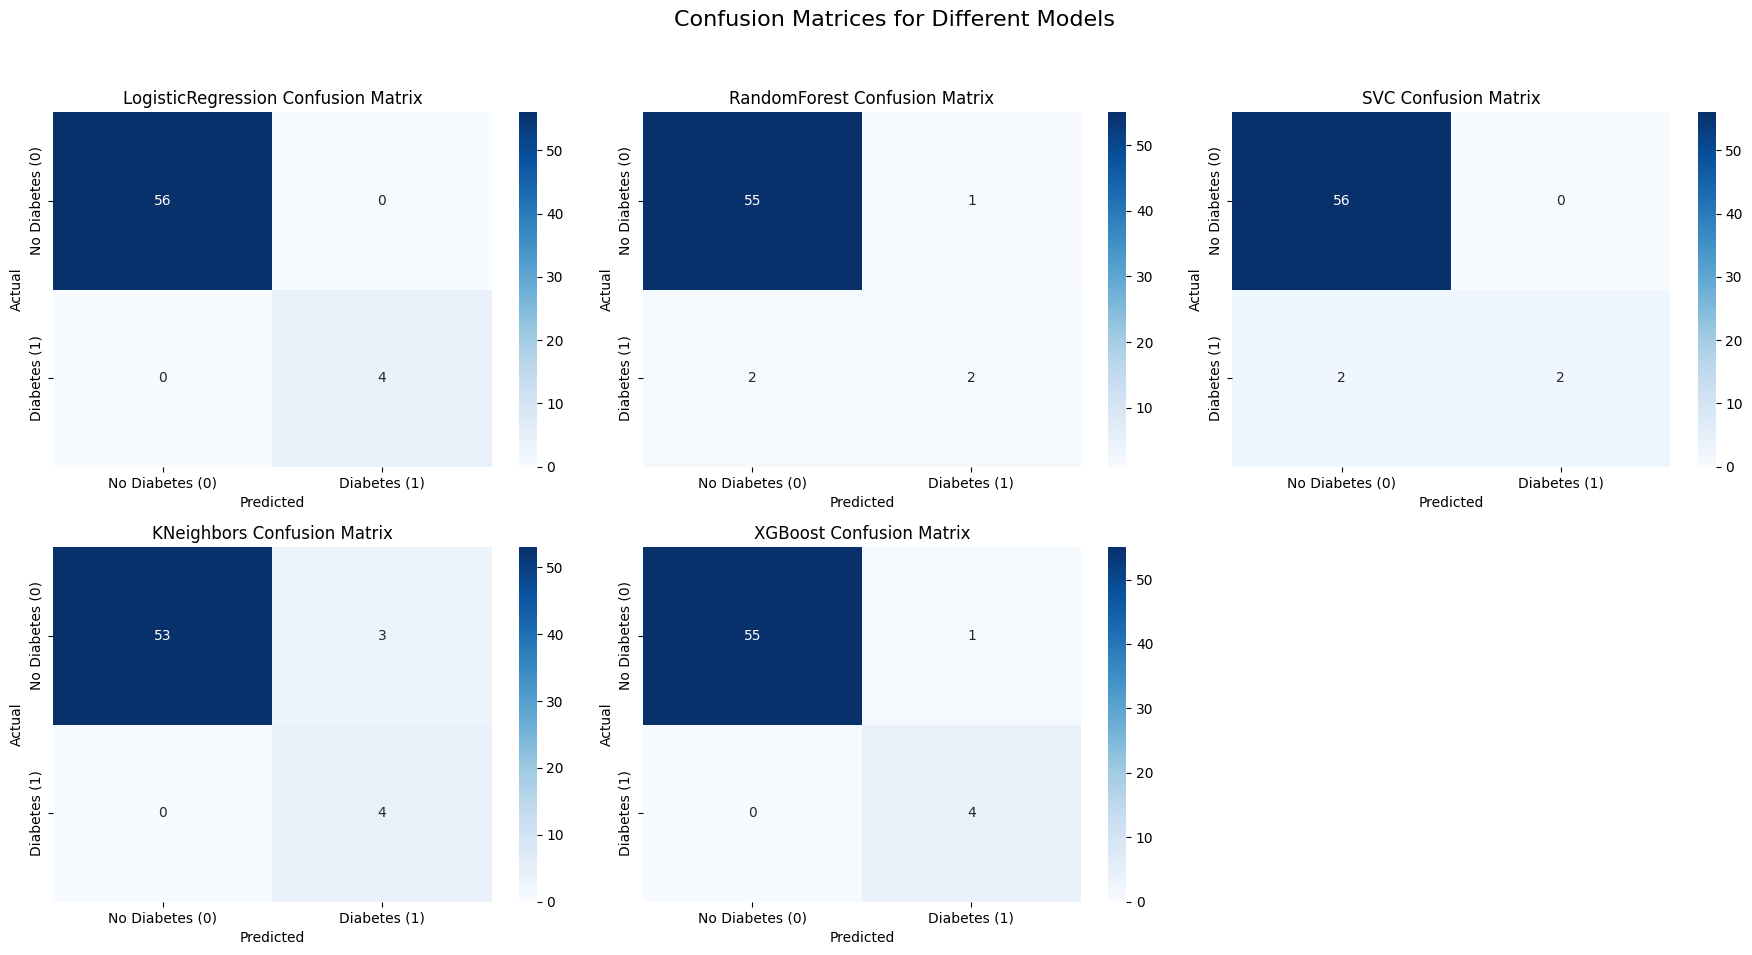

In [38]:


# Labels for the confusion matrix
labels = ['No Diabetes (0)', 'Diabetes (1)']

# Calculate grid dimensions dynamically
num_models = len(results)
num_cols = 3 # You can adjust this for better layout
num_rows = math.ceil(num_models / num_cols)

# Create a figure to hold multiple subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 6, num_rows * 5))
fig.suptitle('Confusion Matrices for Different Models', fontsize=16)

# Flatten axes array for easy iteration if num_rows > 1
if num_rows > 1:
    axes = axes.flatten()

for i, (name, info) in enumerate(results.items()):
    cm = info['confusion_matrix']
    ax = axes[i] if num_rows > 1 else axes
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

# Hide any unused subplots
for j in range(num_models, num_rows * num_cols):
    fig.delaxes(axes[j])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


#**24.Using XGBoost for real time prediction**

In [39]:
# --- Feature List (Must match the columns used for training) ---
input_features = ['chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'age', 'bp.1s', 'bp.1d', 'time.ppn']

# --- Collect User Input ---
user_data = {}
print("Please enter the following details for the individual:")
for feature in input_features:
    while True:
        try:
            value = float(input(f"Enter value for {feature}: "))
            user_data[feature] = value
            break
        except ValueError:
            print("Invalid input. Please enter a numerical value.")

# --- Create DataFrame from User Input ---
user_df = pd.DataFrame([user_data])
print("\nUser Input Data:")
display(user_df)

# --- Preprocessing Steps (using previously fitted scaler and pca) ---
# Ensure 'scaler' and 'pca' objects are available from the previous run
# If you ran the entire pipeline cell, they should be in memory.

# 1. Scale the user input
user_scaled = scaler.transform(user_df)
user_scaled_df = pd.DataFrame(user_scaled, columns=input_features)
print("\nScaled User Data:")
display(user_scaled_df)

# 2. Apply PCA to the scaled input
user_pca = pca.transform(user_scaled)
user_pca_df = pd.DataFrame(user_pca, columns=[f'PC{i+1}' for i in range(user_pca.shape[1])])
print("\nPCA Transformed User Data:")
display(user_pca_df)

# --- Make Prediction using the best model (XGBoost was the highest performing) ---
# Ensure 'models' dictionary is available from the previous run
# If you ran the entire pipeline cell, it should be in memory.

xgb_model = models['XGBoost']
prediction = xgb_model.predict(user_pca)
prediction_proba = xgb_model.predict_proba(user_pca)[:, 1] # Probability of class 1 (diabetes)

print("\n--- Prediction Result ---")
if prediction[0] == 1:
    print(f"The model predicts: DIABETES (Probability: {prediction_proba[0]:.2f})")
else:
    print(f"The model predicts: NO DIABETES (Probability: {1 - prediction_proba[0]:.2f})")

print("\nNote: This is a single prediction and should be interpreted with caution. The model's performance was evaluated on a larger dataset.")

Please enter the following details for the individual:
Enter value for chol: 56
Enter value for stab.glu: 12
Enter value for hdl: 25
Enter value for ratio: 56
Enter value for glyhb: 55
Enter value for age: 5
Enter value for bp.1s: 4
Enter value for bp.1d: 4
Enter value for time.ppn: 
Invalid input. Please enter a numerical value.
Enter value for time.ppn: 6

User Input Data:


,chol,stab.glu,hdl,ratio,glyhb,age,bp.1s,bp.1d,time.ppn
0,56.0,12.0,25.0,56.0,55.0,5.0,4.0,4.0,6.0



Scaled User Data:


,chol,stab.glu,hdl,ratio,glyhb,age,bp.1s,bp.1d,time.ppn
0,-3.916542,-5.011022,-1.781783,37.980194,68.677703,-2.493165,-7.396387,-6.49357,-1.180407



PCA Transformed User Data:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,35.546556,-26.175124,-20.267845,11.278697,1.981507,-13.240901,53.901446



--- Prediction Result ---
The model predicts: DIABETES (Probability: 1.00)

Note: This is a single prediction and should be interpreted with caution. The model's performance was evaluated on a larger dataset.


In [41]:
import joblib

# Define file paths for saving
pca_filename = '/content/pca_model.pkl'
scaler_filename = '/content/scaler.pkl'
xgb_model_filename = '/content/xgboost_model.pkl'

# Save the PCA object
joblib.dump(pca, pca_filename)
print(f"PCA model saved to {pca_filename}")

# Save the StandardScaler object
joblib.dump(scaler, scaler_filename)
print(f"Scaler saved to {scaler_filename}")

# Save the XGBoost model (assuming 'XGBoost' is the key for the best model in 'models' dictionary)
xgb_model = models['XGBoost']
joblib.dump(xgb_model, xgb_model_filename)
print(f"XGBoost model saved to {xgb_model_filename}")

PCA model saved to /content/pca_model.pkl
Scaler saved to /content/scaler.pkl
XGBoost model saved to /content/xgboost_model.pkl
